<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Experiment 5: Bias–Variance, Overfitting and Underfitting Analysis

This experiment demonstrates the concepts of underfitting, optimal fit, and overfitting using polynomial regression on a synthetic house pricing dataset. It also quantifies bias² and variance through repeated resampling.
```

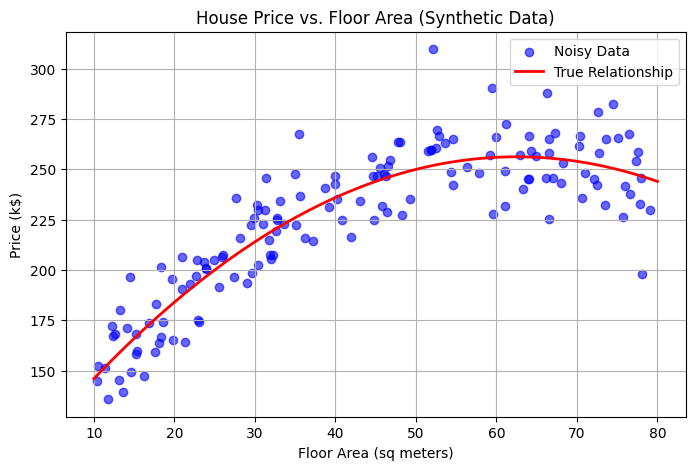

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

# Set seed for reproducibility
np.random.seed(42)

# 1. Generate Synthetic Dataset (150 noisy samples)
# True relationship: Price = 100 + 5 * Area - 0.05 * Area^2 + Noise
X = np.sort(np.random.uniform(10, 80, 150))[:, np.newaxis]
# Non-linear function with added noise
true_fun = lambda x: 100 + 5 * x - 0.04 * x**2
y = true_fun(X).ravel() + np.random.normal(0, 15, 150)

# Split into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Plot the dataset
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.6, label='Noisy Data')
x_plot = np.linspace(10, 80, 200)[:, np.newaxis]
plt.plot(x_plot, true_fun(x_plot), color='red', label='True Relationship', linewidth=2)
plt.title('House Price vs. Floor Area (Synthetic Data)')
plt.xlabel('Floor Area (sq meters)')
plt.ylabel('Price (k$)')
plt.legend()
plt.grid(True)
plt.show()

```markdown
## Task 1 & 2: Fit Polynomial Models & Plot Fitted Curves
We will fit polynomials of degrees 1, 3, 9, and 15, then visualize how they capture the data trend.
```

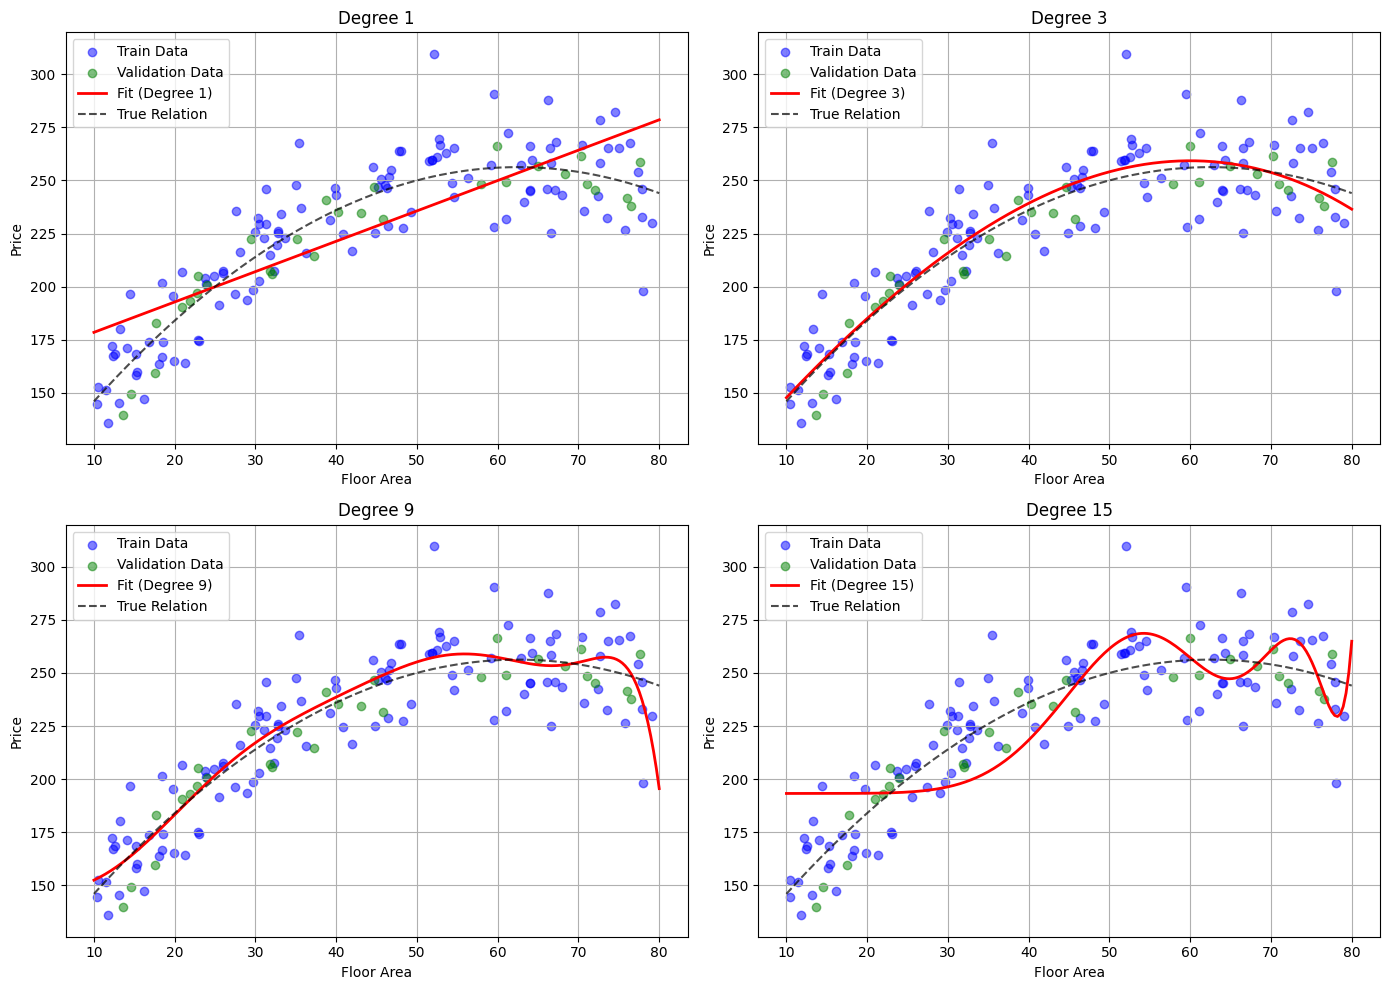

In [2]:
degrees = [1, 3, 9, 15]
plt.figure(figsize=(14, 10))

for i, degree in enumerate(degrees):
    ax = plt.subplot(2, 2, i + 1)

    # Pipeline combining polynomial features and linear regression
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)

    # Predict over plot space
    y_plot_pred = model.predict(x_plot)

    # Plot results
    ax.scatter(X_train, y_train, color='blue', alpha=0.5, label='Train Data')
    ax.scatter(X_val, y_val, color='green', alpha=0.5, label='Validation Data')
    ax.plot(x_plot, y_plot_pred, color='red', linewidth=2, label=f'Fit (Degree {degree})')
    ax.plot(x_plot, true_fun(x_plot), color='black', linestyle='--', alpha=0.7, label='True Relation')

    ax.set_title(f'Degree {degree}')
    ax.set_xlabel('Floor Area')
    ax.set_ylabel('Price')
    ax.set_ylim(min(y) - 10, max(y) + 10)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

```markdown
## Task 3: Training and Validation Error vs. Model Complexity
Let's plot how model complexity (polynomial degree) affects Train MSE and Validation MSE.
```

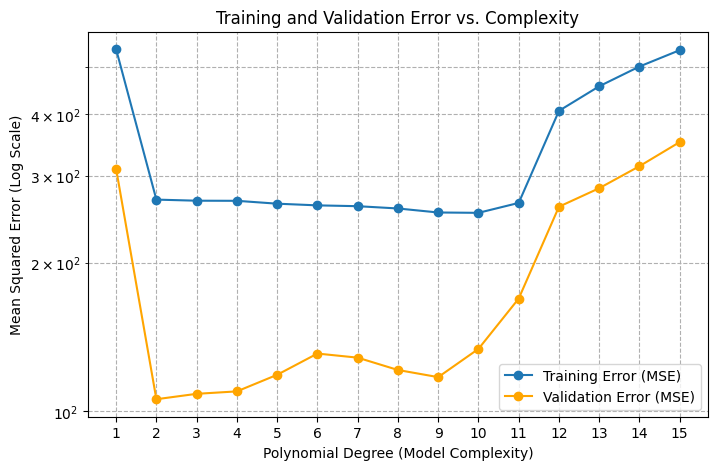

In [3]:
all_degrees = np.arange(1, 16)
train_errors = []
val_errors = []

for d in all_degrees:
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(X_train, y_train)

    # Calculate MSE
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    train_errors.append(mean_squared_error(y_train, y_train_pred))
    val_errors.append(mean_squared_error(y_val, y_val_pred))

# Plot validation curves
plt.figure(figsize=(8, 5))
plt.plot(all_degrees, train_errors, label='Training Error (MSE)', marker='o')
plt.plot(all_degrees, val_errors, label='Validation Error (MSE)', marker='o', color='orange')
plt.yscale('log') # Use log scale because error of degree 15 can be extremely large
plt.xlabel('Polynomial Degree (Model Complexity)')
plt.ylabel('Mean Squared Error (Log Scale)')
plt.title('Training and Validation Error vs. Complexity')
plt.xticks(all_degrees)
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

```markdown
## Task 4: Estimate Bias² and Variance through Bootstrapping (Resampling)
We will generate multiple bootstrap training sets to estimate the predictions' average target values, from which we compute squared Bias and Variance.
```

Degree  1 | Bias^2:   222.20 | Variance:     7.20 | Total Error estimate:   229.39
Degree  3 | Bias^2:     4.76 | Variance:     6.48 | Total Error estimate:    11.24
Degree  9 | Bias^2:    46.63 | Variance:    16.62 | Total Error estimate:    63.25
Degree 15 | Bias^2:   283.39 | Variance:    57.94 | Total Error estimate:   341.33


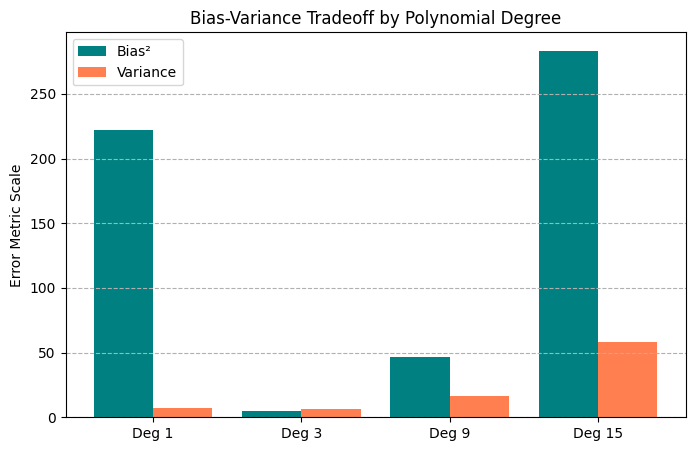

In [4]:
n_bootstraps = 200
# We will evaluate bias and variance on a fixed test grid
X_test = np.linspace(10, 80, 100)[:, np.newaxis]
y_test_true = true_fun(X_test).ravel()

bias_sq_results = []
variance_results = []
total_error_results = []

for d in degrees:
    predictions = np.zeros((n_bootstraps, len(X_test)))

    # Repeat resampling
    for b in range(n_bootstraps):
        # Resample dataset with replacement
        X_resampled, y_resampled = resample(X, y, random_state=b)

        model = make_pipeline(PolynomialFeatures(d), LinearRegression())
        model.fit(X_resampled, y_resampled)
        predictions[b, :] = model.predict(X_test)

    # Calculate metrics across bootstrapping
    # Mean prediction over the different training sets
    mean_prediction = np.mean(predictions, axis=0)

    # Bias^2: (Mean prediction - True value)^2
    bias_sq = np.mean((mean_prediction - y_test_true) ** 2)

    # Variance: Mean variance of predictions at each point
    variance = np.mean(np.var(predictions, axis=0))

    bias_sq_results.append(bias_sq)
    variance_results.append(variance)

    print(f"Degree {d:2d} | Bias^2: {bias_sq:8.2f} | Variance: {variance:8.2f} | Total Error estimate: {bias_sq + variance:8.2f}")

# Plot Bias-Variance Tradeoff
plt.figure(figsize=(8, 5))
x_indices = np.arange(len(degrees))
plt.bar(x_indices - 0.2, bias_sq_results, width=0.4, label='Bias²', color='teal')
plt.bar(x_indices + 0.2, variance_results, width=0.4, label='Variance', color='coral')
plt.xticks(x_indices, [f'Deg {d}' for d in degrees])
plt.title('Bias-Variance Tradeoff by Polynomial Degree')
plt.ylabel('Error Metric Scale')
plt.legend()
plt.grid(True, axis='y', linestyle='--')
plt.show()

```markdown
## Task 5: Model Selection & Justification

Based on the analysis:
- **Degree 1** (Underfitting): High Bias² and low Variance. The model cannot capture the inherent non-linear trend.
- **Degree 3** (Optimal Fit): Lowest validation error and well-balanced trade-off between Bias² and Variance. It matches the underlying parabolic quadratic trend perfectly.
- **Degrees 9 & 15** (Overfitting): Low Bias on training data but extremely high Variance. Minor changes in the bootstrap datasets lead to vastly different curves, resulting in explosive validation errors.

**Conclusion:** Degree 3 is the best choice.
```